# Model 3: Fine-Tuned Pretrained Model

Goal of this model is to take a pretrained convolutional neural network (VGG16) and adapt it to our custom dataset using fine-tuning. Model 3 partially unfreezes the convolutional base and allows higher-level pretrained filters to adjust to the new data.

In [1]:
# Core
import numpy as np
import os
import pathlib
import random

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom

# Pretrained models
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

# Image loading and preprocessing
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation
from sklearn.metrics import confusion_matrix, classification_report

# Utilities
import pandas as pd
from collections import Counter

C:\Users\ronis\anaconda3\envs\keras\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 1.14.6 when it was built against 1.14.5, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


### Load preprocessed data

Found 260 files belonging to 5 classes.
Using 221 files for training.
Found 260 files belonging to 5 classes.
Using 39 files for validation.
Found 51 files belonging to 5 classes.
Train:
  book: 45
  cat: 44
  dog: 36
  mug: 42
  rabbit: 54

Validation:
  book: 5
  cat: 9
  dog: 6
  mug: 8
  rabbit: 11

Test:
  book: 10
  cat: 10
  dog: 11
  mug: 10
  rabbit: 10



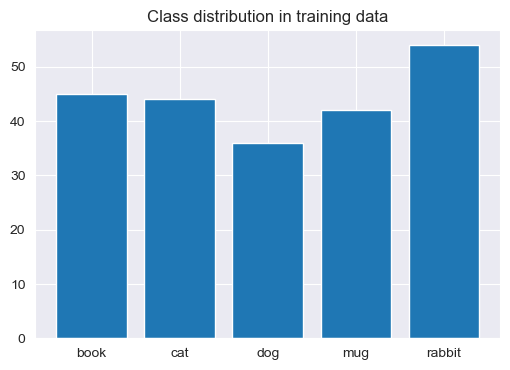

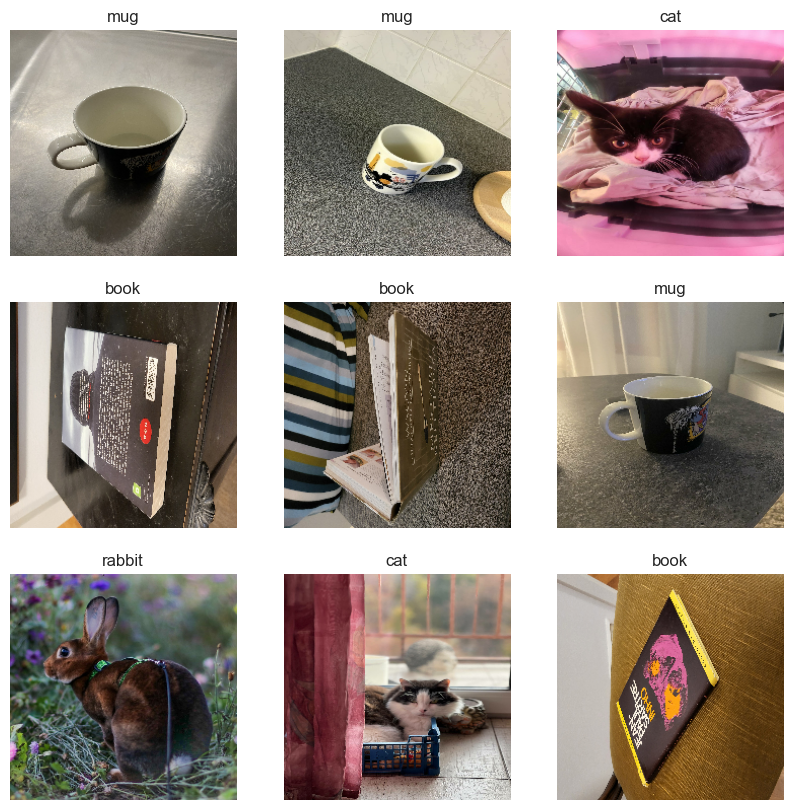

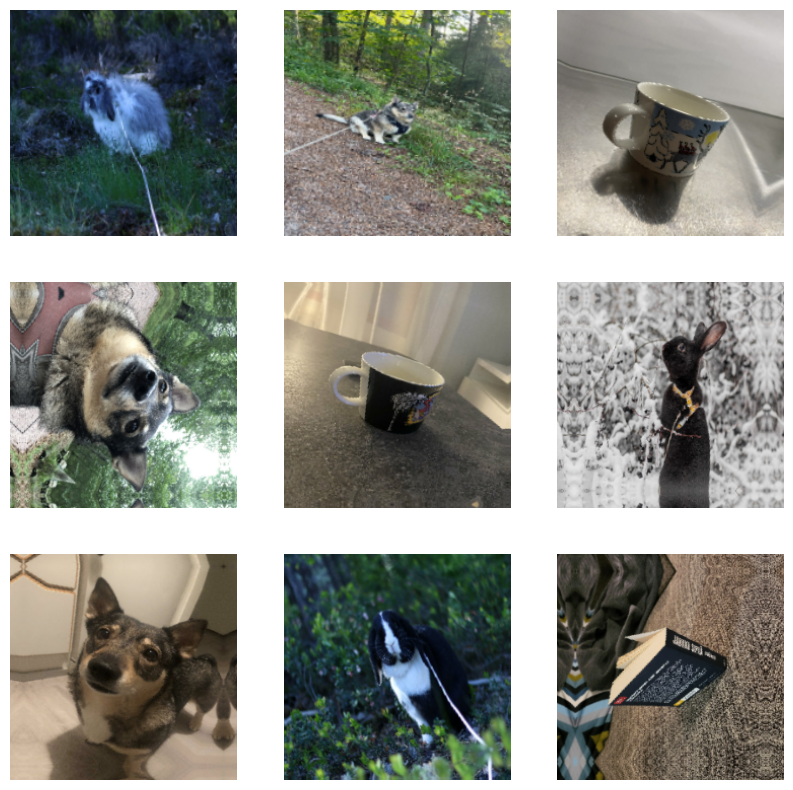

In [2]:
import import_ipynb
from preprocessing import train_ds, val_ds, test_ds, class_names, data_augmentation, normalization_layer

# run this cell again to delete output from preprocessing

### Model Architecture

The model consists of three main parts:

- Preprocessing, data augmentation and normalization to prepare images for VGG16.

- Pretrained backbone, VGG16 with ImageNet weights, loaded without the classification head and initially kept frozen.

- Classification head, a global average pooling layer, dropout for regularization, and a final Dense layer for class prediction.

In [3]:
IMG_SIZE = train_ds.element_spec[0].shape[1:3]
NUM_CLASSES = len(class_names)

print("Image size:", IMG_SIZE)
print("Classes:", class_names)


Image size: (224, 224)
Classes: ['book', 'cat', 'dog', 'mug', 'rabbit']


In [4]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=IMG_SIZE + (3,)
)

# Everything frozen, no fine-tuning yet
base_model.trainable = False

base_model.summary()


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
inputs = keras.Input(shape=IMG_SIZE + (3,))

x = data_augmentation(inputs)
x = normalization_layer(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,717,253 (56.14 MB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
EPOCHS_INITIAL = 11

history_initial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_INITIAL
)


Epoch 1/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 31s 4s/step - accuracy: 0.2036 - loss: 1.9694 - val_accuracy: 0.0769 - val_loss: 1.7413
Epoch 2/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 28s 4s/step - accuracy: 0.2036 - loss: 1.8717 - val_accuracy: 0.3333 - val_loss: 1.5565
Epoch 3/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 26s 4s/step - accuracy: 0.2308 - loss: 1.6954 - val_accuracy: 0.6667 - val_loss: 1.4457
Epoch 4/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 4s/step - accuracy: 0.3167 - loss: 1.6055 - val_accuracy: 0.6154 - val_loss: 1.3719
Epoch 5/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.3575 - loss: 1.5420 - val_accuracy: 0.6410 - val_loss: 1.3213
Epoch 6/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.4208 - loss: 1.4538 - val_accuracy: 0.7179 - val_loss: 1.2770
Epoch 7/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step - accuracy: 0.3801 - loss: 1.4661 - val_accuracy: 0.7179 - val_loss: 1.2310
Epoch 8/11
7/7 ━━━━━━━━━━━━━━━━━━━━ 29s 4s/step - accuracy: 0.4480 - loss: 1.3600 - val_accuracy: 0.8205 - val_loss: 1.1881
Epoch 9/

### Initial Training

During the initial training stage, all convolutional layers of VGG16 are frozen. 

Only the new Dense classification head is trained. 
Validation accuracy increased steadily during this stage, and no signs of overfitting were observed.

In [7]:

base_model.trainable = True

fine_tune_at = 10

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_FINE = 9

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE
)


Epoch 1/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 6s/step - accuracy: 0.6561 - loss: 1.0640 - val_accuracy: 0.7692 - val_loss: 0.7951
Epoch 2/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 6s/step - accuracy: 0.6742 - loss: 0.9092 - val_accuracy: 0.8205 - val_loss: 0.6149
Epoch 3/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 40s 6s/step - accuracy: 0.7692 - loss: 0.7557 - val_accuracy: 0.8205 - val_loss: 0.5079
Epoch 4/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 6s/step - accuracy: 0.7919 - loss: 0.6062 - val_accuracy: 0.8462 - val_loss: 0.4712
Epoch 5/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 6s/step - accuracy: 0.8235 - loss: 0.4786 - val_accuracy: 0.8462 - val_loss: 0.4278
Epoch 6/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 44s 6s/step - accuracy: 0.8507 - loss: 0.4467 - val_accuracy: 0.8462 - val_loss: 0.4290
Epoch 7/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 6s/step - accuracy: 0.8824 - loss: 0.3758 - val_accuracy: 0.8462 - val_loss: 0.5190
Epoch 8/9
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 6s/step - accuracy: 0.8959 - loss: 0.3351 - val_accuracy: 0.8974 - val_loss: 0.3456
Epoch 9/9
7/7 ━━

### Fine-Tuning results

Top layers of VGG16 were unfrozen and trained with a very low learning rate. This allowed the model to adjust higher-level features to our dataset while preserving the earlier pretrained filters.
Fine-tuning improved validation accuracy significantly (0.87–0.92) and the training and validation curves stayed close.

In [8]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8824 - loss: 0.2566
Test accuracy: 0.882
Test loss: 0.257


## Evaluation

The accuracy on the test set is around 88%, indicating good generalization to unseen data. However, this is not better than Model 2, which achieved 96% accuracy with a custom FCN architecture. This suggests that for this specific dataset, a good pretrained model like VGG16 is well suited.

### Training and Validation Curves


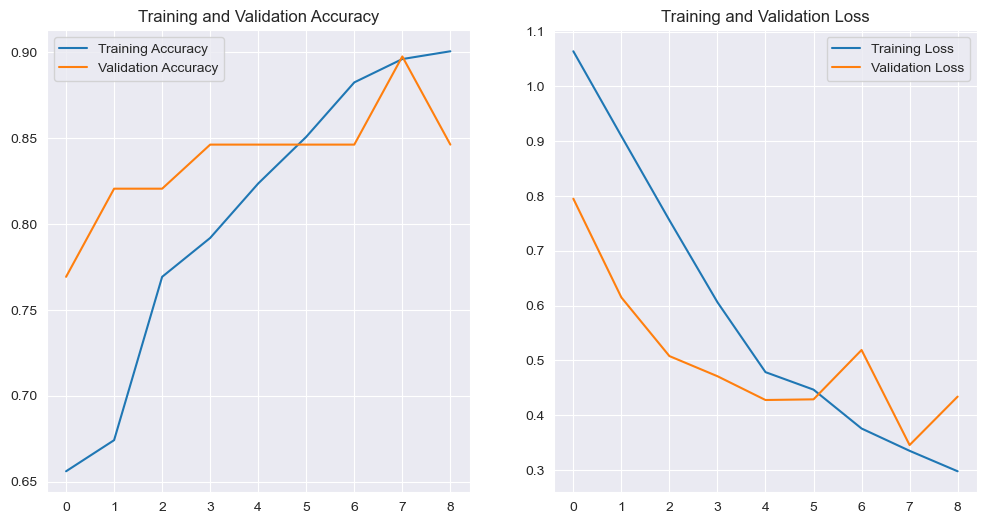

In [11]:
acc = history_fine.history['accuracy']
val_acc = history_fine.history['val_accuracy']
loss = history_fine.history['loss']
val_loss = history_fine.history['val_loss']

epochs = range(len(acc))

# Plot training  and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

As we can see from the plots, both training and validation accuracy improved steadily during fine-tuning, reaching over 90%. The loss curves also decreased smoothly without significant changes, indicating that the model did not overfit during this stage.

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


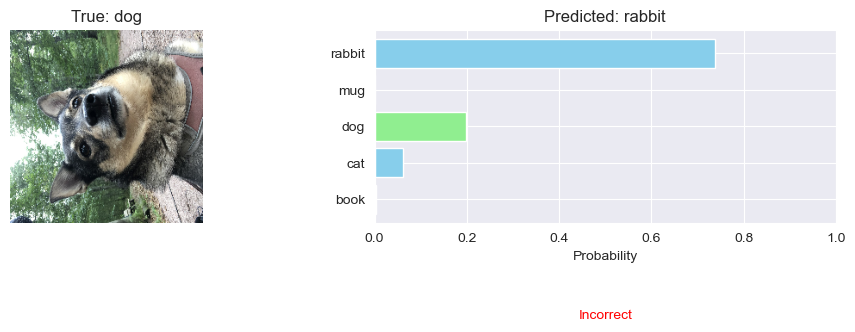

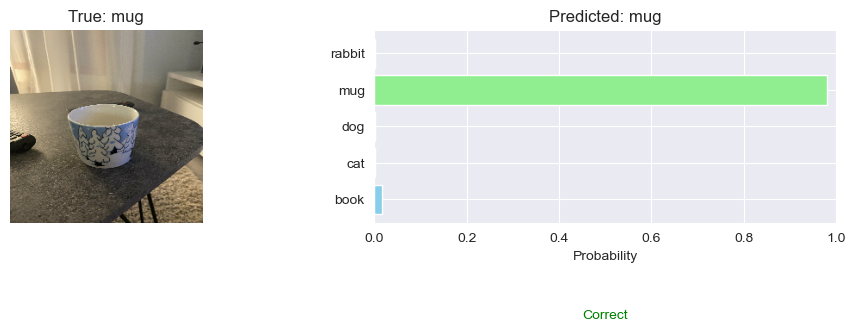

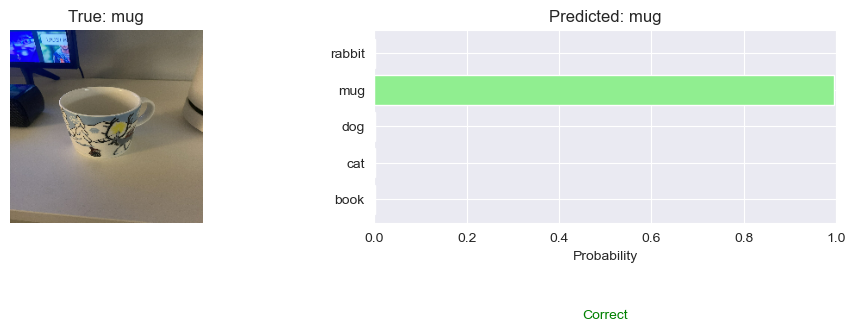

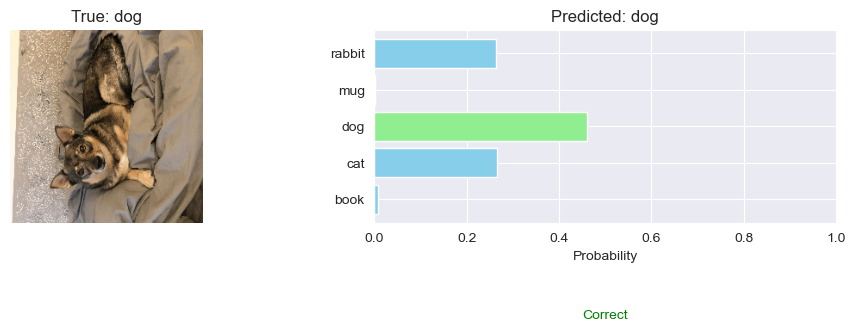

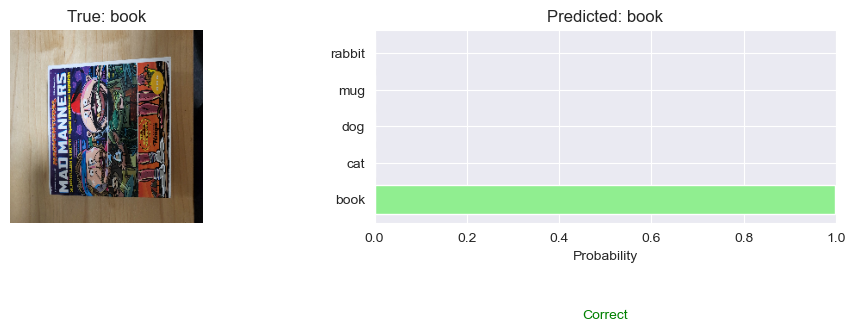

In [10]:
# Pick one batch from test dataset
test_images, test_labels = next(iter(test_ds.take(1)))

# Predictions for the batch
predictions = model.predict(test_images)

# Convert to ints (sparse → already integers)
true_labels = test_labels.numpy()
predicted_labels = np.argmax(predictions, axis=1)

def plot_images(model):
    y_pred = []
    x_images = []
    y_true = []

    # Go through test_ds and collect everything
    for images, labels in test_ds:
        preds = model.predict(images, batch_size=32)
        y_pred.extend(preds)
        x_images.extend(images.numpy())
        y_true.extend(labels.numpy())   # sparse labels = integers

    y_pred = np.array(y_pred)
    x_images = np.array(x_images)
    y_true = np.array(y_true)

    # Random 5 samples
    num_samples = 5
    random_indices = random.sample(range(len(x_images)), num_samples)

    for i in random_indices:
        plt.figure(figsize=(10, 4))

        # LEFT: image
        plt.subplot(1, 2, 1)
        plt.imshow(x_images[i].astype("uint8"))
        true_class = class_names[int(y_true[i])]
        plt.title(f"True: {true_class}")
        plt.axis("off")

        # RIGHT: bar chart of predicted probabilities
        plt.subplot(1, 2, 2)
        pred_prob = y_pred[i]
        predicted_class = class_names[np.argmax(pred_prob)]

        # color bars: mark correct class green
        colors = [
            "lightgreen" if class_names[j] == true_class else "skyblue"
            for j in range(len(class_names))
        ]

        plt.barh(class_names, pred_prob, color=colors)
        plt.xlabel("Probability")
        plt.title(f"Predicted: {predicted_class}")
        plt.xlim([0, 1])

        # Add Correct/Incorrect label
        if predicted_class != true_class:
            plt.text(0.5, -0.5, "Incorrect", color="red",
                     ha="center", transform=plt.gca().transAxes)
        else:
            plt.text(0.5, -0.5, "Correct", color="green",
                     ha="center", transform=plt.gca().transAxes)

        plt.tight_layout()
        plt.show()


plot_images(model)

### Comparison with Previous Models

The table below shows the comparison between Model 1 (custom CNN model), Model 2 (pretrained VGG16 feature extraction model) and Model 3 (pretrained fine-tuned model).

|  | Model 1 | Model 2 | Model 3                                    |
| --- | --- | --- |--------------------------------------------|
| Accuracy | 54.9% | 96.1% | 88.2%                                      |
| Loss behaviour | Training loss sometimes rebounces after dropping near zero and validation loss is unstable. | Similar pattern as in Model 1 but less rebouncing and more stable. | Stable loss curves with little rebouncing. |
| Validation curves | Noisier validation curves. | Smoother and steadier validation curves. | Smooth validation curves indicating stable optimization. |
| Overfitting/Generalization | Shows strong overfitting. Large gap between train and validation and low training loss and higher validation loss. | No effect. High performance on training, limited additional generalization on validation/test. | No effect. High performance on training, limited additional generalization on validation/test. |


Model 2 and 3 have smoother validation that suggests more stable optimization, but neither model achieves notably better generalization in current setup. The accuracy in Model 2 is highest at 96.1%, while Model 3 achieves 88.2%. This indicates that for this specific dataset, a well-designed custom FCN architecture (Model 2) outperforms the fine-tuned pretrained model (Model 3).

### Conclusion

Model 3, a fine-tuned VGG16 model, achieved good performance with 88.2% accuracy on the test set. Fine-tuning the top layers of VGG16 allowed the model to adapt higher-level features to our dataset, resulting in smooth training and validation curves without overfitting. However, Model 2, which used VGG16 as a fixed feature extractor with a custom classification head, outperformed Model 3 with 96.1% accuracy.